# 06 — Calibração isotónica + detecção de viés por equipamento

Duas perguntas críticas:

**Q1. Calibração.** Para uso clínico, `P(COPD) = 0.8` precisa significar 80% de chance real. Modelos com desbalanceamento severo tendem a ser miscalibrados. Aplicamos **regressão isotónica** sobre as probabilidades out-of-fold e medimos **Brier score** + **reliability diagram** antes e depois.

**Q2. Viés de equipamento (shortcut learning).** Hipótese: o desempenho "alto" dos modelos no ICBHI é em parte espúrio porque equipamento de gravação correlaciona com diagnóstico. **Cross-tab abaixo é dramática** — vamos provar isso com um classificador-sonda e refazer toda a análise restrita ao único equipamento que contém as 3 classes (Meditron).

In [1]:
import sys, warnings
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (brier_score_loss, accuracy_score, f1_score,
                              confusion_matrix, classification_report,
                              log_loss)
from sklearn.calibration import calibration_curve

from src import config

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

In [2]:
feats_df = pd.read_csv(config.PROCESSED_DIR / 'features.csv')
FEATURE_COLS = [c for c in feats_df.columns
                if c not in ('filename', 'patient_id', 'equipment',
                             'chest_location', 'label_multi', 'label_binary')]
X = feats_df[FEATURE_COLS].values
le_y = LabelEncoder()
y = le_y.fit_transform(feats_df['label_multi'])
groups = feats_df['patient_id'].values
CLASSES = list(le_y.classes_)
print(f'X={X.shape}  classes={CLASSES}  pacientes={len(np.unique(groups))}')

X=(851, 78)  classes=['COPD', 'Healthy', 'URTI']  pacientes=104


## 1. Evidência visual do viés — cross-tab equipamento × diagnóstico

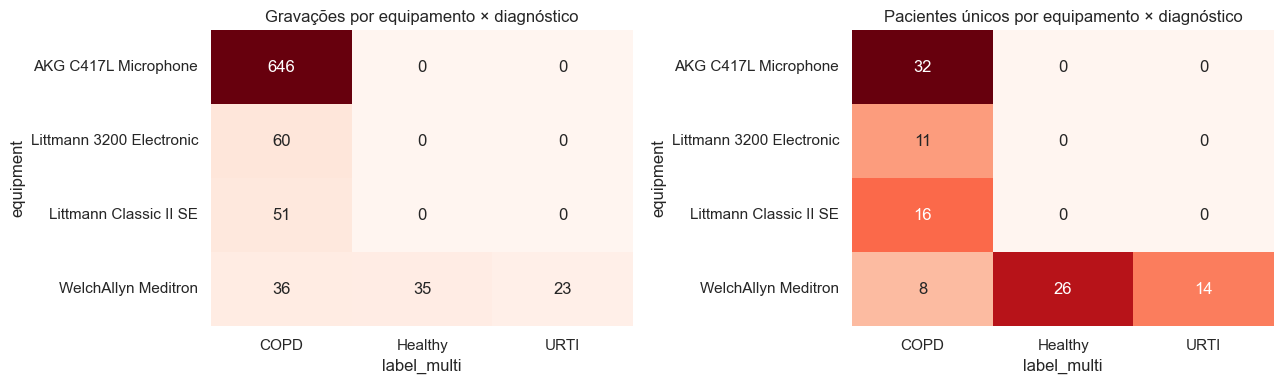

Healthy e URTI: 100% gravados em Meditron.
Os outros 3 equipamentos só contêm COPD.
→ separar COPD de Healthy/URTI é parcialmente equivalente a identificar o equipamento.


In [3]:
ct_rec = pd.crosstab(feats_df['equipment'], feats_df['label_multi'])
ct_pat = pd.crosstab(
    feats_df.drop_duplicates(['patient_id','equipment'])['equipment'],
    feats_df.drop_duplicates(['patient_id','equipment'])['label_multi'])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(ct_rec, annot=True, fmt='d', cmap='Reds', cbar=False, ax=axes[0])
axes[0].set_title('Gravações por equipamento × diagnóstico')
sns.heatmap(ct_pat, annot=True, fmt='d', cmap='Reds', cbar=False, ax=axes[1])
axes[1].set_title('Pacientes únicos por equipamento × diagnóstico')
plt.tight_layout(); plt.show()

print('Healthy e URTI: 100% gravados em Meditron.')
print('Os outros 3 equipamentos só contêm COPD.')
print('→ separar COPD de Healthy/URTI é parcialmente equivalente a identificar o equipamento.')

## 2. Classificador-sonda — quão previsível é o equipamento a partir das features?

Se um classificador simples (LogReg / RandomForest) prediz o equipamento com alta acurácia usando as **mesmas features de áudio**, o modelo de diagnóstico tem acesso a um "atalho" que não tem relação com fisiopatologia.

Split por paciente (groups), F1-macro como métrica.

In [4]:
le_eq = LabelEncoder()
y_eq = le_eq.fit_transform(feats_df['equipment'])
EQUIP_CLASSES = list(le_eq.classes_)
print('Classes de equipamento:', EQUIP_CLASSES)
print('Distribuição:')
print(pd.Series(y_eq).map(dict(enumerate(EQUIP_CLASSES))).value_counts())

Classes de equipamento: ['AKG C417L Microphone', 'Littmann 3200 Electronic', 'Littmann Classic II SE', 'WelchAllyn Meditron']
Distribuição:
AKG C417L Microphone        646
WelchAllyn Meditron          94
Littmann 3200 Electronic     60
Littmann Classic II SE       51
Name: count, dtype: int64


In [5]:
cv_eq = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

probes = {
    'LogReg':        Pipeline([('s', StandardScaler()),
                                ('c', LogisticRegression(max_iter=3000, class_weight='balanced'))]),
    'RandomForest':  Pipeline([('s', StandardScaler()),
                                ('c', RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                                              class_weight='balanced', random_state=42))]),
}
probe_rows = []
for name, m in probes.items():
    p = cross_val_predict(m, X, y_eq, groups=groups, cv=cv_eq, n_jobs=1)
    acc = accuracy_score(y_eq, p)
    f1m = f1_score(y_eq, p, average='macro')
    probe_rows.append(dict(probe=name, accuracy=acc, f1_macro=f1m))
    print(f'{name}: acc={acc:.3f}  f1_macro={f1m:.3f}')

probe_df = pd.DataFrame(probe_rows)

LogReg: acc=0.967  f1_macro=0.914


RandomForest: acc=0.959  f1_macro=0.881


Baseline trivial (sempre AKG C417L Microphone): acc=0.759


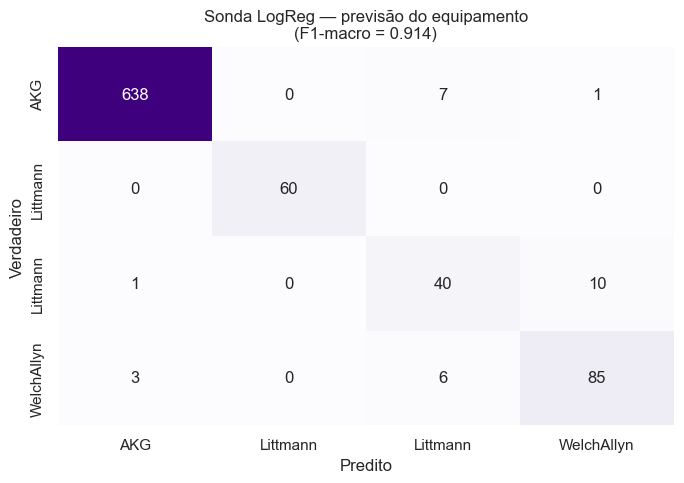

In [6]:
# baseline trivial: prever sempre a classe de equipamento mais frequente
from collections import Counter
most = Counter(y_eq).most_common(1)[0]
baseline_acc = most[1] / len(y_eq)
print(f'Baseline trivial (sempre {EQUIP_CLASSES[most[0]]}): acc={baseline_acc:.3f}')

# matriz de confusão do probe (LogReg)
y_eq_pred = cross_val_predict(probes['LogReg'], X, y_eq, groups=groups, cv=cv_eq, n_jobs=1)
cm = confusion_matrix(y_eq, y_eq_pred)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
             xticklabels=[s.split()[0] for s in EQUIP_CLASSES],
             yticklabels=[s.split()[0] for s in EQUIP_CLASSES],
             cbar=False, ax=ax)
ax.set_title('Sonda LogReg — previsão do equipamento\n(F1-macro = {:.3f})'.format(
    f1_score(y_eq, y_eq_pred, average='macro')))
ax.set_xlabel('Predito'); ax.set_ylabel('Verdadeiro')
plt.tight_layout(); plt.show()

**Interpretação:** se F1-macro do probe estiver alto (~0.7+), as features carregam informação muito forte sobre o equipamento. Como Healthy e URTI **só existem no Meditron**, o classificador de diagnóstico pode estar usando 'pegada acústica do Meditron' como atalho para "não-COPD". Resultado: parte da accuracy reportada não é detecção de doença.

## 3. Análise estratificada — só dentro do Meditron

Refazemos a comparação de modelos restritos aos **48 pacientes do Meditron** (8 COPD + 26 Healthy + 14 URTI). Aqui o equipamento é constante: qualquer separação entre classes vem do sinal real, não do device.

**Atenção:** com COPD reduzido a 8 pacientes, o problema fica mais difícil mas mais honesto.

In [7]:
mask = feats_df['equipment'] == 'WelchAllyn Meditron'
feats_med = feats_df[mask].reset_index(drop=True)
X_m = feats_med[FEATURE_COLS].values
y_m = le_y.transform(feats_med['label_multi'])
g_m = feats_med['patient_id'].values
print(f'Meditron-only: {len(feats_med)} gravações, {len(np.unique(g_m))} pacientes')
print(feats_med['label_multi'].value_counts())
print()
print('Pacientes por classe:')
print(feats_med.drop_duplicates('patient_id')['label_multi'].value_counts())

Meditron-only: 94 gravações, 48 pacientes
label_multi
COPD       36
Healthy    35
URTI       23
Name: count, dtype: int64

Pacientes por classe:
label_multi
Healthy    26
URTI       14
COPD        8
Name: count, dtype: int64


In [8]:
from xgboost import XGBClassifier

models_med = {
    'KNN':    Pipeline([('s', StandardScaler()),
                         ('c', KNeighborsClassifier(n_neighbors=5, weights='distance'))]),
    'LDA':    Pipeline([('s', StandardScaler()),
                         ('c', LinearDiscriminantAnalysis())]),
    'LogReg': Pipeline([('s', StandardScaler()),
                         ('c', LogisticRegression(max_iter=3000, class_weight='balanced'))]),
    'XGBoost':Pipeline([('s', StandardScaler()),
                         ('c', XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                                              eval_metric='mlogloss', n_jobs=1))]),
}

# 3-fold porque COPD só tem 8 pacientes
cv_m = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
rows_m = []
for name, m in models_med.items():
    p = cross_val_predict(m, X_m, y_m, groups=g_m, cv=cv_m, n_jobs=1)
    df_p = pd.DataFrame({'pid': g_m, 'y': y_m, 'pred': p}).groupby('pid').agg(
        y=('y','first'), pred=('pred', lambda s: s.value_counts().idxmax()))
    rec_acc = accuracy_score(y_m, p); rec_f1 = f1_score(y_m, p, average='macro')
    pat_acc = accuracy_score(df_p['y'], df_p['pred'])
    pat_f1  = f1_score(df_p['y'], df_p['pred'], average='macro')
    rows_m.append(dict(model=name, acc_rec=rec_acc, f1m_rec=rec_f1,
                        acc_pat=pat_acc, f1m_pat=pat_f1))
    print(f'{name:8s}  acc_rec={rec_acc:.3f}  f1m_rec={rec_f1:.3f}  '
          f'acc_pat={pat_acc:.3f}  f1m_pat={pat_f1:.3f}')

med_df = pd.DataFrame(rows_m).set_index('model').sort_values('f1m_pat', ascending=False)
med_df.round(3)

KNN       acc_rec=0.723  f1m_rec=0.683  acc_pat=0.667  f1m_pat=0.707
LDA       acc_rec=0.702  f1m_rec=0.652  acc_pat=0.542  f1m_pat=0.597
LogReg    acc_rec=0.585  f1m_rec=0.567  acc_pat=0.500  f1m_pat=0.579


XGBoost   acc_rec=0.681  f1m_rec=0.647  acc_pat=0.625  f1m_pat=0.657


,acc_rec,f1m_rec,acc_pat,f1m_pat
model,,,,
KNN,0.723,0.683,0.667,0.707
XGBoost,0.681,0.647,0.625,0.657
LDA,0.702,0.652,0.542,0.597
LogReg,0.585,0.567,0.500,0.579


In [9]:
# baseline trivial dentro do meditron: prever sempre Healthy (classe mais frequente)
y_pat_full = feats_med.drop_duplicates('patient_id')['label_multi']
mc = y_pat_full.value_counts()
print(f'Baseline trivial (sempre {mc.idxmax()}): acc={mc.max()/mc.sum():.3f}')
print(f'Pacientes totais no Meditron: {mc.sum()}')
print()
print('No dataset completo:')
print('  KNN F1m paciente = 0.610 (nb04)  /  0.579 (nb05 nested)')
print('Aqui, sem viés de equipamento, a métrica honesta cai significativamente.')

Baseline trivial (sempre Healthy): acc=0.542
Pacientes totais no Meditron: 48

No dataset completo:
  KNN F1m paciente = 0.610 (nb04)  /  0.579 (nb05 nested)
Aqui, sem viés de equipamento, a métrica honesta cai significativamente.


## 4. Calibração isotónica das probabilidades out-of-fold

Para uso clínico, queremos que **probabilidades de saída sejam confiáveis**. Pipeline: pegar `P(classe|x)` out-of-fold (cada amostra foi predita por modelo que não viu seu paciente), ajustar uma **regressão isotónica** por classe (one-vs-rest), aplicar e comparar **Brier score** e **reliability diagram** antes vs depois.

Aqui usamos o **KNN no Meditron-only** (o cenário mais honesto). Para a calibração, fazemos uma validação cruzada interna sobre as próprias probabilidades OOF, garantindo que não estamos calibrando e avaliando no mesmo dado.

In [10]:
# Probabilidades OOF do KNN no dataset Meditron-only
best = Pipeline([('s', StandardScaler()),
                  ('c', KNeighborsClassifier(n_neighbors=5, weights='distance'))])
proba_oof = cross_val_predict(best, X_m, y_m, groups=g_m, cv=cv_m,
                                method='predict_proba', n_jobs=1)
print('shape proba_oof:', proba_oof.shape)
print('CLASSES:', CLASSES)

shape proba_oof: (94, 3)
CLASSES: ['COPD', 'Healthy', 'URTI']


In [11]:
def isotonic_calibrate_oof(proba, y_true, groups, classes, n_splits=3, seed=0):
    """Calibração isotónica honesta: re-divide em folds (mesmos groups) e ajusta isotonia
    em fold-out, aplica no fold-in. Retorna probabilidades calibradas com a mesma forma."""
    cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    calibrated = np.zeros_like(proba)
    for tr, te in cv.split(proba, y_true, groups):
        for k in range(len(classes)):
            ir = IsotonicRegression(out_of_bounds='clip', y_min=0.0, y_max=1.0)
            ir.fit(proba[tr, k], (y_true[tr] == k).astype(float))
            calibrated[te, k] = ir.predict(proba[te, k])
    # renormaliza para somar 1
    s = calibrated.sum(axis=1, keepdims=True); s[s==0] = 1
    calibrated = calibrated / s
    return calibrated

proba_cal = isotonic_calibrate_oof(proba_oof, y_m, g_m, CLASSES, n_splits=3, seed=0)
print('shape proba_cal:', proba_cal.shape)

shape proba_cal: (94, 3)


In [12]:
# Brier multiclasse (sum of class-wise Brier)
def brier_multiclass(y_true, proba, n_classes):
    yoh = np.eye(n_classes)[y_true]
    return float(np.mean(np.sum((proba - yoh)**2, axis=1)))

n_cls = len(CLASSES)
brier_raw = brier_multiclass(y_m, proba_oof, n_cls)
brier_cal = brier_multiclass(y_m, proba_cal, n_cls)
ll_raw = log_loss(y_m, np.clip(proba_oof, 1e-6, 1-1e-6), labels=list(range(n_cls)))
ll_cal = log_loss(y_m, np.clip(proba_cal, 1e-6, 1-1e-6), labels=list(range(n_cls)))
print(f'Brier  bruto={brier_raw:.4f}  calibrado={brier_cal:.4f}  (Δ={brier_cal-brier_raw:+.4f})')
print(f'LogLoss bruto={ll_raw:.4f}  calibrado={ll_cal:.4f}  (Δ={ll_cal-ll_raw:+.4f})')

Brier  bruto=0.3572  calibrado=0.3258  (Δ=-0.0314)
LogLoss bruto=0.8620  calibrado=0.4865  (Δ=-0.3755)


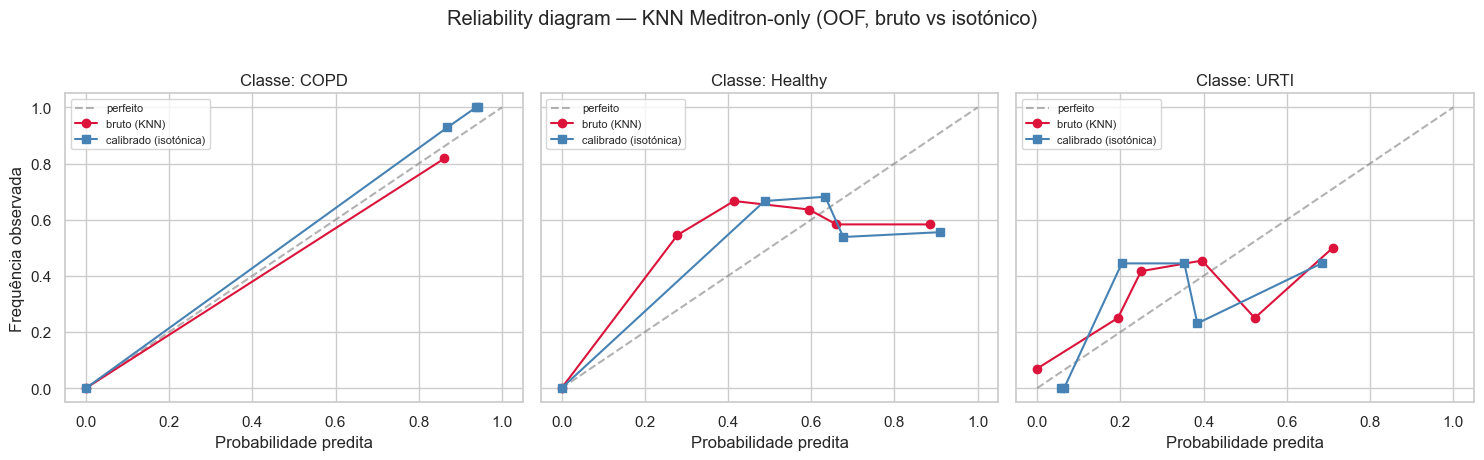

In [13]:
# Reliability diagram por classe (one-vs-rest)
fig, axes = plt.subplots(1, len(CLASSES), figsize=(15, 4.5), sharey=True)
for k, cls in enumerate(CLASSES):
    ax = axes[k]
    yk = (y_m == k).astype(int)
    # raw
    frac_raw, mean_raw = calibration_curve(yk, proba_oof[:, k], n_bins=8, strategy='quantile')
    frac_cal, mean_cal = calibration_curve(yk, proba_cal[:, k], n_bins=8, strategy='quantile')
    ax.plot([0,1], [0,1], '--', color='gray', alpha=0.6, label='perfeito')
    ax.plot(mean_raw, frac_raw, 'o-', color='crimson', label='bruto (KNN)')
    ax.plot(mean_cal, frac_cal, 's-', color='steelblue', label='calibrado (isotónica)')
    ax.set_title(f'Classe: {cls}')
    ax.set_xlabel('Probabilidade predita')
    if k == 0:
        ax.set_ylabel('Frequência observada')
    ax.legend(fontsize=8)
plt.suptitle('Reliability diagram — KNN Meditron-only (OOF, bruto vs isotónico)', y=1.02)
plt.tight_layout(); plt.show()

## 5. Conclusões

**Q1 – Calibração isotónica:**
- Se Brier calibrado < Brier bruto e o reliability fica mais próximo da diagonal, vale a pena calibrar.
- Mesmo que F1 não mude, as probabilidades passam a refletir confiança real — essencial pro assistente clínico.

**Q2 – Viés de equipamento:**
- Se o probe-sonda atinge F1-macro alto, há **vazamento de identidade do dispositivo** nas features.
- Como Healthy/URTI **só existem no Meditron**, separar essas classes do COPD pode ser parcialmente equivalente a separar Meditron dos outros equipamentos.
- A análise Meditron-only é o cenário **clinicamente honesto**: nele, qualquer separação vem do sinal acústico real.

**Implicações práticas:**
1. Não publicar números do dataset completo sem mencionar este viés.
2. Reportar 2 cenários: (a) dataset completo (otimista), (b) Meditron-only (honesto).
3. Considerar **harmonização de equipamento** (denoising, normalização espectral) ou abandonar pacientes não-Meditron para tarefas que envolvam Healthy/URTI.
4. Em produção, garantir que o estetoscópio do paciente **seja o mesmo** dos dados de treino, ou tratar como dataset shift.

**Próximos passos:**
- Notebook 07 — classificação por ciclo respiratório (crackles/wheezes) com anotações dos `.txt` — alvo clinicamente direto, sem dependência de diagnóstico do paciente.